# Exploring the Data

In [204]:
import sys
import airfrans as af
from pathlib import Path
import matplotlib.pyplot as plt
from matplotlib.collections import LineCollection
import numpy as np
import pandas as pd
import json
import math

sys.path.append(str(Path().resolve().parent/"src"))
from parse_name import parse_name

In [205]:
# Load and Explore one Simulation
DATA_PATH = ROOT_DIR = Path().resolve().parent/"data"/"Dataset"
# Load first simulation
name = "airFoil2D_SST_31.68_0.424_0.273_4.301_1.0_11.616"

simulation = af.Simulation(DATA_PATH, name)
print(f"Position: \nShape: {simulation.position.shape} \nContents: {simulation.position}")
print(f"\nPressure: \nShape: {simulation.pressure.shape} \nContents: {simulation.pressure}")
print(f"\nVelocity: \nShape: {simulation.velocity.shape} \nContents: {simulation.velocity}")
print(f"\n Nodes: \nShape{simulation.surface.shape} \nContents: {simulation.surface} \nTrue Count: {sum(simulation.surface)}")



Position: 
Shape: (181559, 2) 
Contents: [[ 4.21555805  0.02379554]
 [ 4.21557379  0.02377923]
 [ 3.99052548  0.02213027]
 ...
 [-2.12518358 -1.54503381]
 [-2.13902926 -1.53453517]
 [-2.15289736 -1.52373278]]

Pressure: 
Shape: (181559, 1) 
Contents: [[0.81042659]
 [0.81041783]
 [0.92984182]
 ...
 [1.99334681]
 [1.9953779 ]
 [1.99734902]]

Velocity: 
Shape: (181559, 2) 
Contents: [[29.40725899  0.174483  ]
 [29.40690994  0.17448676]
 [29.31901741  0.17132579]
 ...
 [31.61639595  0.23234282]
 [31.61634445  0.23292962]
 [31.61629486  0.23352142]]

 Nodes: 
Shape(181559,) 
Contents: [False False False ... False False False] 
True Count: 1023


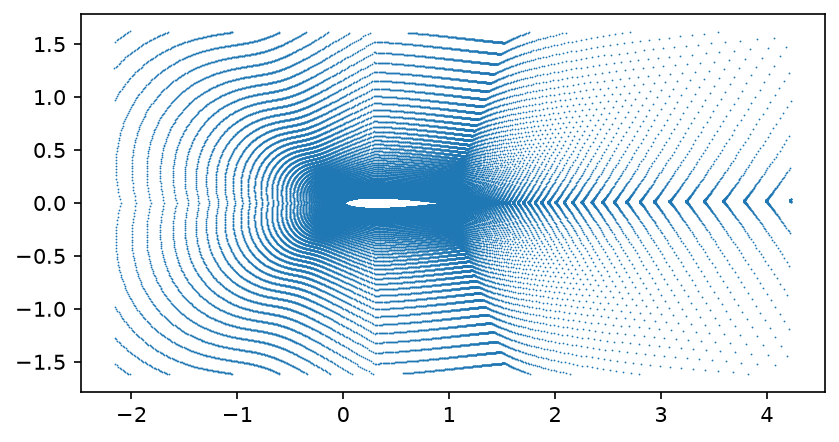

In [206]:
plt.rcParams['figure.dpi'] = 150
fig, ax = plt.subplots()

ax.scatter(simulation.position[:,0],simulation.position[:,1],s=0.75,linewidths = 0)
ax.set_aspect("equal")

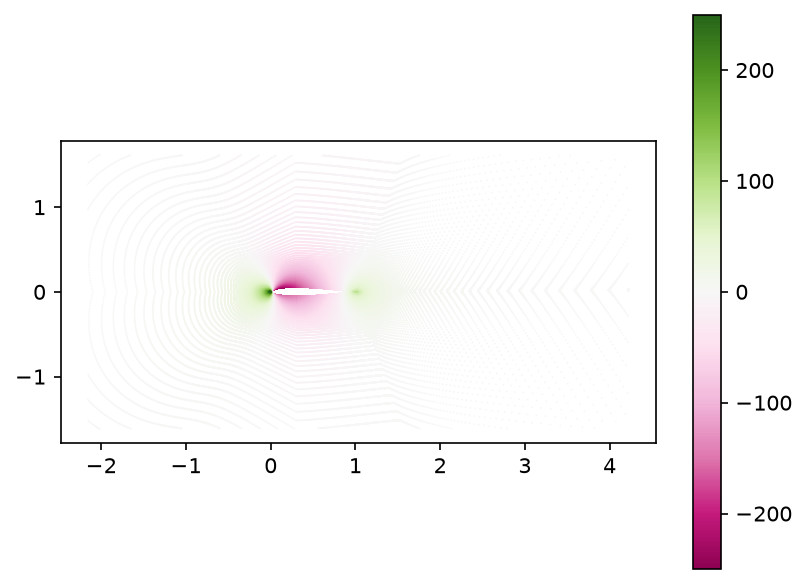

In [207]:
# Colour points based on pressure
fig,ax = plt.subplots()
plot = ax.scatter(simulation.position[:,0],simulation.position[:,1],c=simulation.pressure,cmap="PiYG",s=0.75, linewidths = 0,
    vmax=250,vmin=-250)
ax.set_aspect("equal")
fig.colorbar(plot,ax=ax)
# High pressure right on the tip of the airfoil, lower pressure on the top of the airfoil which i guess
# makes sense as the lift means its pushing air down

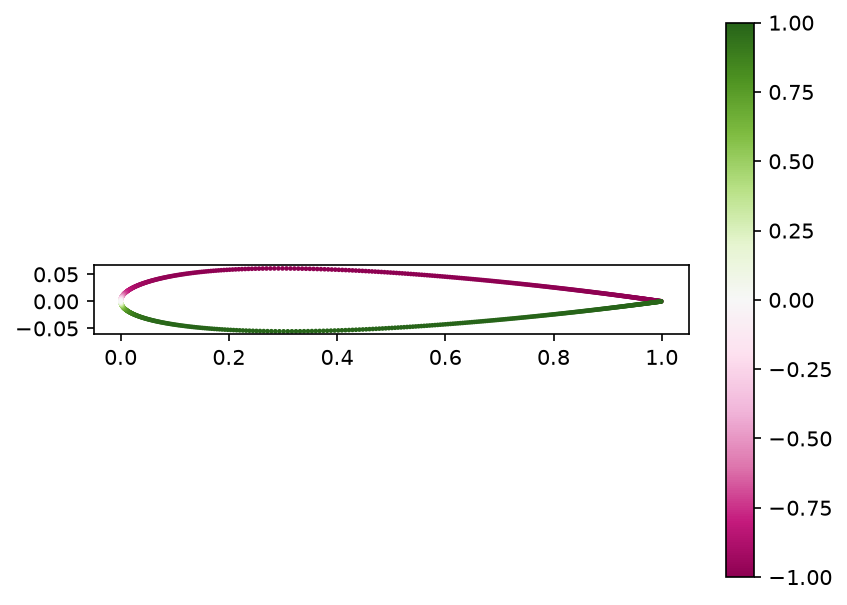

In [208]:
# Exploring pressure away the surface
mask = simulation.surface
pos = simulation.position[mask]
nrm = simulation.normals[mask]

fig,ax = plt.subplots()
plot = ax.scatter(pos[:,0],pos[:,1],c=nrm[:,1],cmap="PiYG",s=5, linewidths = 0)
ax.set_aspect("equal")
fig.colorbar(plot,ax=ax)



        

Text(0, 0.5, 'Cp - Coefficient of Pressure')

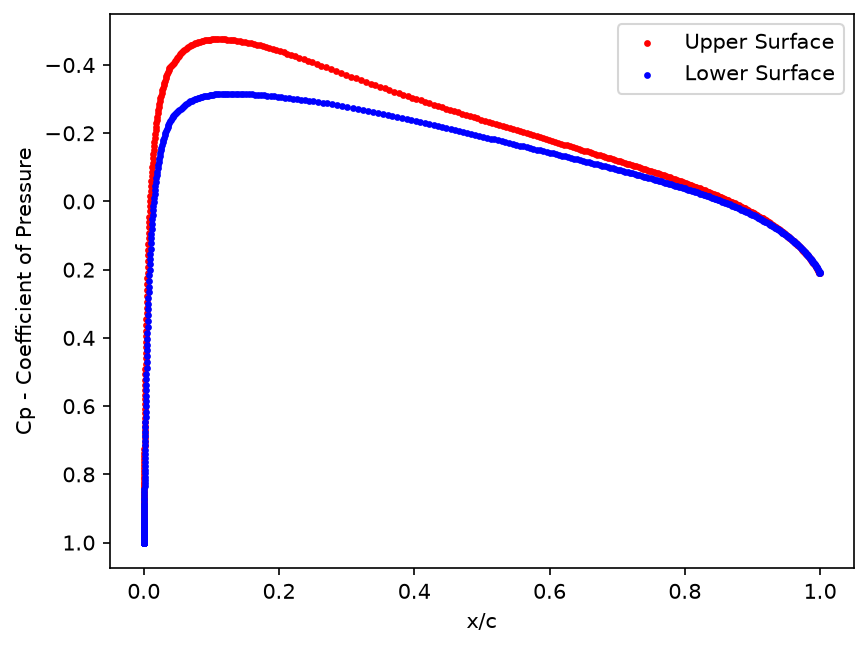

In [209]:
mask = simulation.surface
pos = simulation.position[mask]
prs = simulation.pressure[mask,0]
nrm = simulation.normals[mask]
dymprs = 0.5 * simulation.inlet_velocity**2
cp = prs/dymprs
upper_mask = nrm[:,1]<=0
lower_mask = nrm[:,1]>0



fig,ax = plt.subplots()

#Upper Scatter
ax.scatter(pos[upper_mask,0],cp[upper_mask],s=5,label="Upper Surface",c="RED")
ax.scatter(pos[lower_mask,0],cp[lower_mask],s=5,label="Lower Surface",c="BLUE")

ax.invert_yaxis()
ax.legend()
ax.set_xlabel("x/c")
ax.set_ylabel("Cp - Coefficient of Pressure")

In [210]:
with open(DATA_PATH/"manifest.json",'r') as json_file:
    manifest = json.load(json_file)

df = pd.DataFrame([{"name":n} | parse_name(n) for n in manifest["full_train"]+manifest["full_test"]])

df["RE"] = df["inletVelocity"] * 1.0/1.56e-5

df.head()



,name,inletVelocity,angleOfAttack,L,P,Q,XX,M,RE
0,airFoil2D_SST_36.622_11.319_3.941_5.424_1.0_16...,36.622,11.319,3.941,5.424,True,16.283,NaN,2.347564e+06
1,airFoil2D_SST_58.831_-3.563_2.815_4.916_10.078,58.831,-3.563,NaN,4.916,NaN,10.078,2.815,3.771218e+06
2,airFoil2D_SST_43.327_8.905_4.236_6.511_10.744,43.327,8.905,NaN,6.511,NaN,10.744,4.236,2.777372e+06
3,airFoil2D_SST_89.151_4.462_0.974_4.094_1.0_19.856,89.151,4.462,0.974,4.094,True,19.856,NaN,5.714808e+06
4,airFoil2D_SST_87.422_2.992_1.895_3.128_1.0_10.656,87.422,2.992,1.895,3.128,True,10.656,NaN,5.603974e+06


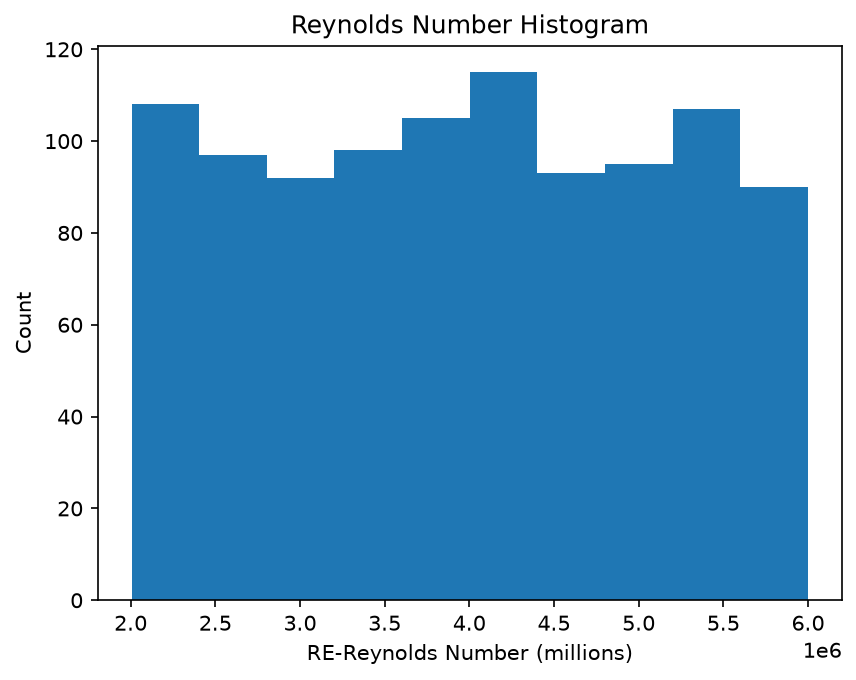

In [211]:
plt.hist(df["RE"])
plt.title("Reynolds Number Histogram")
plt.xlabel("RE-Reynolds Number (millions)")
plt.ylabel("Count")
plt.show()

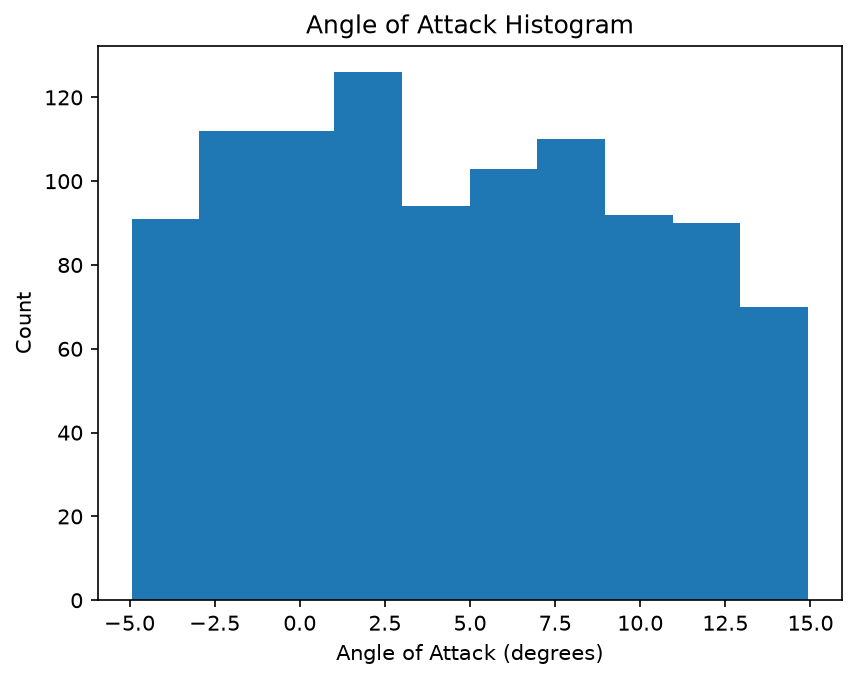

In [212]:
plt.hist(df["angleOfAttack"])
plt.title("Angle of Attack Histogram")
plt.xlabel("Angle of Attack (degrees)")
plt.ylabel("Count")
plt.show()

Text(0, 0.5, 'Count')

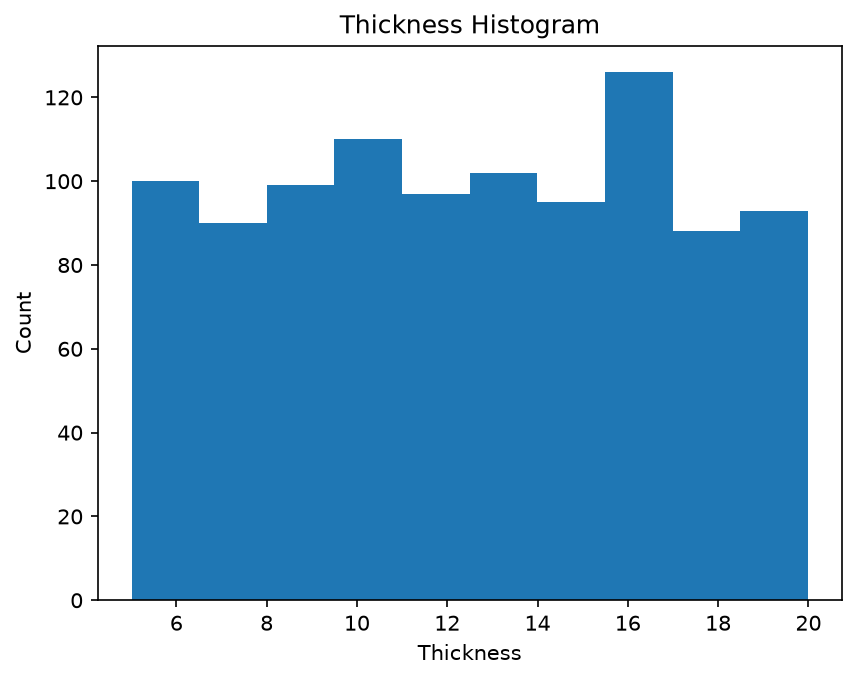

In [213]:
plt.hist(df["XX"])
plt.title("Thickness Histogram")
plt.xlabel("Thickness")
plt.ylabel("Count")

In [214]:
df["family"] = np.where(df["L"].isna(),"4-digit","5-digit")

print(df["family"].value_counts())

family
5-digit    511
4-digit    489
Name: count, dtype: int64


In [215]:
aoa_train = set(manifest["aoa_train"])
aoa_test = set(manifest["aoa_test"])

df["set"] = np.select([
    df["name"].isin(aoa_train),
    df["name"].isin(aoa_test),],    
    ["aoa_train","aoa_test"],
    default = "None")

print(df["set"].value_counts() ,"\nSum: " , sum(df["set"].value_counts()))



set
aoa_train    804
aoa_test     196
Name: count, dtype: int64 
Sum:  1000


In [216]:
df.head()

,name,inletVelocity,angleOfAttack,L,P,Q,XX,M,RE,family,set
0,airFoil2D_SST_36.622_11.319_3.941_5.424_1.0_16...,36.622,11.319,3.941,5.424,True,16.283,NaN,2.347564e+06,5-digit,aoa_train
1,airFoil2D_SST_58.831_-3.563_2.815_4.916_10.078,58.831,-3.563,NaN,4.916,NaN,10.078,2.815,3.771218e+06,4-digit,aoa_test
2,airFoil2D_SST_43.327_8.905_4.236_6.511_10.744,43.327,8.905,NaN,6.511,NaN,10.744,4.236,2.777372e+06,4-digit,aoa_train
3,airFoil2D_SST_89.151_4.462_0.974_4.094_1.0_19.856,89.151,4.462,0.974,4.094,True,19.856,NaN,5.714808e+06,5-digit,aoa_train
4,airFoil2D_SST_87.422_2.992_1.895_3.128_1.0_10.656,87.422,2.992,1.895,3.128,True,10.656,NaN,5.603974e+06,5-digit,aoa_train


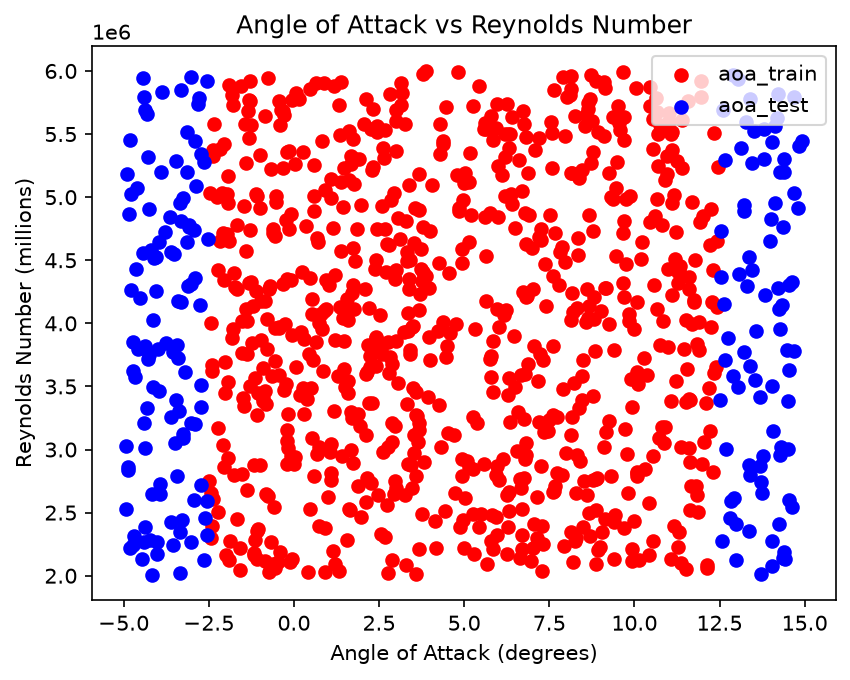

In [217]:
train_mask = df["set"] == "aoa_train"
test_mask = df["set"] == "aoa_test"



fig, ax = plt.subplots()
ax.scatter(df["angleOfAttack"][train_mask],df["RE"][train_mask],c="RED",label="aoa_train")
ax.scatter(df["angleOfAttack"][test_mask],df["RE"][test_mask],c="BLUE",label="aoa_test")
ax.set_title("Angle of Attack vs Reynolds Number")
ax.set_xlabel("Angle of Attack (degrees)")
ax.set_ylabel("Reynolds Number (millions)")
ax.legend()

In [218]:
sample = df.sample(20,random_state=0)
for foil in sample["name"]:
    print(foil)
    sim = af.Simulation(DATA_PATH,foil)
    print(len(sim.position))

airFoil2D_SST_59.245_2.515_1.376_6.044_17.151
175872
airFoil2D_SST_61.301_0.196_6.046_2.274_10.855
183814
airFoil2D_SST_35.823_8.293_0.329_6.252_0.0_11.422
181700
airFoil2D_SST_55.541_9.902_1.288_4.79_0.0_16.92
181765
airFoil2D_SST_41.343_-4.157_6.892_0.0_19.804
179335
airFoil2D_SST_58.038_-4.278_2.807_7.062_1.0_8.833
177480
airFoil2D_SST_58.363_5.802_5.647_2.966_16.926
178919
airFoil2D_SST_36.228_6.699_2.659_3.41_0.0_9.235
197042
airFoil2D_SST_90.743_14.221_1.897_3.274_8.669
180505
airFoil2D_SST_35.445_12.572_6.569_0.0_16.397
180416
airFoil2D_SST_37.311_0.727_1.911_6.377_1.0_11.313
181116
airFoil2D_SST_61.997_12.253_0.155_7.019_0.0_15.847
180571
airFoil2D_SST_38.237_9.129_0.349_3.678_8.291
181458
airFoil2D_SST_36.385_2.558_2.975_3.104_1.0_9.306
198556
airFoil2D_SST_32.499_12.136_1.194_6.108_1.0_8.121
182506
airFoil2D_SST_34.343_8.933_2.915_3.012_19.934
179772
airFoil2D_SST_46.385_3.538_4.58_2.02_19.22
181011
airFoil2D_SST_37.26_8.498_2.099_4.252_6.054
172502
airFoil2D_SST_41.403_-2.44

---

### Calcualting CL

The coefficient of lift and drag are calculated from the normal force coeffcicent which is calculated from the area between the two lines of the x vs Cp (coefficent of pressure) graph

In [219]:
def area_method_cn(simulation):
    mask = simulation.surface
    pos = simulation.position[mask]
    prs = simulation.pressure[mask,0]
    nrm = simulation.normals[mask]
    dymprs = 0.5 * simulation.inlet_velocity**2
    cp = prs/dymprs
    upper_mask = nrm[:,1]<=0
    lower_mask = nrm[:,1]>0

    # Building DataFrame of simulation
    upper_data = pd.DataFrame({
        "x":pos[upper_mask,0], 
        "y":pos[upper_mask,1],
        "nx":nrm[upper_mask,0],
        "ny":nrm[upper_mask,1],
        "p":prs[upper_mask],
        "cp": cp[upper_mask],
        })
    lower_data = pd.DataFrame({
        "x":pos[lower_mask,0], 
        "y":pos[lower_mask,1],
        "nx":nrm[lower_mask,0],
        "ny":nrm[lower_mask,1],
        "p":prs[lower_mask],
        "cp": cp[lower_mask],
        })

    # Sort by x
    upper_data = upper_data.sort_values("x")
    lower_data = lower_data.sort_values("x")

    # Integrate against the Cp value (y values first)
    upper_integral = np.trapezoid(upper_data["cp"],upper_data["x"])
    lower_integral = np.trapezoid(lower_data["cp"],lower_data["x"])

    Cn = lower_integral - upper_integral

    print(f"Coefficent of normal force = {Cn}")
    print(f"Library's Coefficent = {simulation.force_coefficient()[1][1]}")

    return (Cn, simulation.force_coefficient()[1][1])


area_method_cn(simulation)

Coefficent of normal force = 0.06691363075541168
Library's Coefficent = 0.06675648086207979


(np.float64(0.06691363075541168), np.float64(0.06675648086207979))

Coefficent of normal force = 0.4154758413112024
Library's Coefficent = 0.4156043323487196
Coefficent of normal force = 0.6165122086180882
Library's Coefficent = 0.61639265702237
Coefficent of normal force = 0.903070139049111
Library's Coefficent = 0.9117163377220839
Coefficent of normal force = 1.0815083464615638
Library's Coefficent = 1.0963740640659634
Coefficent of normal force = -0.3945149014755118
Library's Coefficent = -0.3954552293702175
Coefficent of normal force = -0.17278516260605983
Library's Coefficent = -0.17323737065077288
Coefficent of normal force = 1.1108598808359864
Library's Coefficent = 1.1157877093605684
Coefficent of normal force = 0.8947843321523221
Library's Coefficent = 0.9003338352169984
Coefficent of normal force = 1.5655955617719581
Library's Coefficent = 1.6107517885713354
Coefficent of normal force = 1.1990834592046522
Library's Coefficent = 1.2257179862129732
Coefficent of normal force = 0.26538784006589955
Library's Coefficent = 0.26525225378285366
Coeff

Text(0, 0.5, 'Difference')

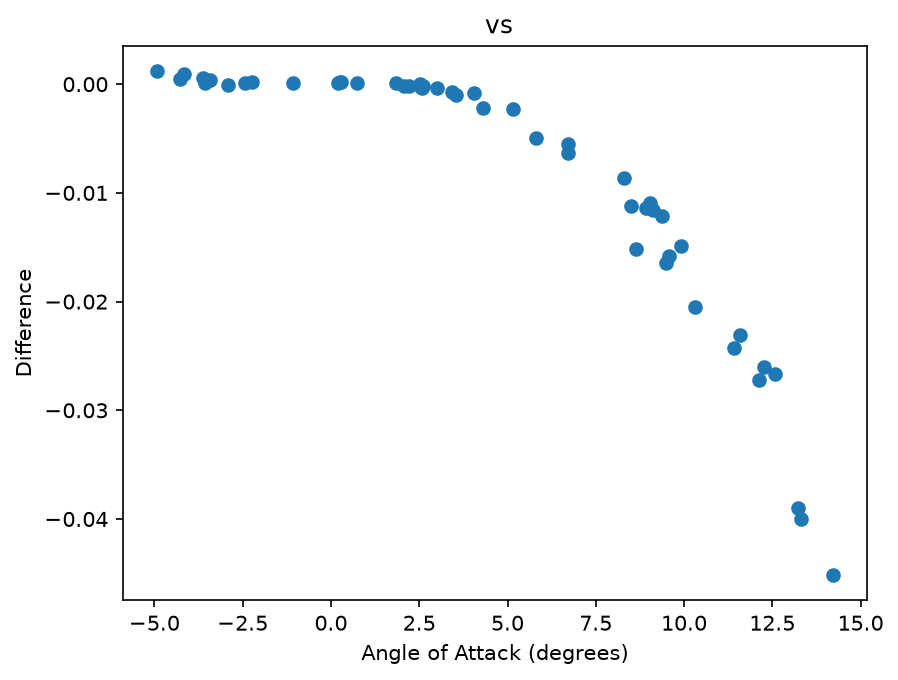

In [220]:
# Run the above method on 50 of the other simulations and plotting the 
# difference between the calculated and libary version

sample = df.sample(50,random_state=0)[["name","angleOfAttack"]]
results = []
for name, ang in zip(sample["name"], sample["angleOfAttack"]):
    sim = af.Simulation(DATA_PATH, name)
    res = area_method_cn(sim)

    results.append((res[0]-res[1],ang))

results = np.array(results)


fig, ax = plt.subplots()
ax.scatter(results[:,1],results[:,0])
ax.set_title(" vs")
ax.set_xlabel("Angle of Attack (degrees)")
ax.set_ylabel("Difference")

Our calculation will not be exact as the librarys value because our doesn't take into account a couple of things:
- The axial force is missing
- Cn isnt exactly Cl

---
### Segment Method

Imagine the airfoil outline as a closed loop made of about 1000 short straight sticks between the points. On each stick, the air presses inwards normal to the stick at some pressure:
>Force on stick = pressure x length x (diretion pointing into the airfoil)

In [221]:
af_mesh = simulation.airfoil
print(af_mesh)
print(af_mesh.lines[:12])
print(len(af_mesh.lines))
print(af_mesh.n_points, af_mesh.n_lines)
print(af_mesh.point_data.keys())
print(af_mesh.point_data["p"])

PolyData (0x1eaced4b0a0)
  N Cells:    1023
  N Points:   1023
  N Strips:   0
  X Bounds:   -7.853e-06, 1.000e+00
  Y Bounds:   -5.538e-02, 6.083e-02
  Z Bounds:   5.000e-01, 5.000e-01
  N Arrays:   10
[2 0 1 2 2 0 2 3 2 2 4 3]
3069
1023 1023
['nut', 'p', 'U', 'Normals']
[-191.992  -189.4105 -194.7805 ... -181.131  -183.76   -186.687 ]


`af_mesh.lines[:12]` is 3 times longer than `n_points` because it assigns 3 values to each point meaning the following:
- N number of points on this line (usually 2)
- index of the point 1
- index of the point 2
The len being exactly 3 times longer means this is a closed loop system

In [234]:
# Turn lines into a table of index pairs
# reshape lines
table = af_mesh.lines.reshape(af_mesh.n_points, 3)
# drop first column of n number of points
table = np.delete(table,0,1)


dymprs = 0.5 * simulation.inlet_velocity**2
perimeter = 0
total_force = np.zeros(2)
for pair in table:
    coord_1 = af_mesh.points[pair[0]][:2]
    coord_2 = af_mesh.points[pair[1]][:2]
    midpoint = (coord_1+coord_2) /2
    length = np.linalg.norm(coord_1-coord_2)

    stick_pressure = (af_mesh.point_data['p'][pair[0]]+af_mesh.point_data['p'][pair[1]])/2
    
    dx, dy = (coord_1-coord_2)/length
    
    norm = (-dy,dx) # tested against segments around x=0.5 with dy

    # Force = normal x pressure * length
    force = np.array(norm) * stick_pressure * length
    total_force = total_force + force

    # if (0.4<midpoint[0]<0.6 and midpoint[1]>0):
    #     print(f"MidPoint = {midpoint},norm = {norm}")
    #     print(f"pressure = {stick_pressure} Normals = {af_mesh.point_data['Normals'][pair][:,:2]}")
    #     #print(f"Norms of Normals = {np.linalg.norm(af_mesh.point_data['Normals'][pair][:,:2], axis = 1)}\n")
    #     print(f"Stick force = {force}")
    perimeter  = perimeter + length

print(f"Surface Perimeter: {perimeter}")
print(f"Total Force: {total_force}")


aoa = np.deg2rad(parse_name(simulation.name)["angleOfAttack"])
drag = total_force[0]*math.cos(aoa) + total_force[1]*math.sin(aoa)
lift = -total_force[0]*math.sin(aoa) + total_force[1]*math.cos(aoa)

#print(f"Calculated Lift:{lift} Drag:{drag}")

# chords all have length of 1
cl_p = lift/ dymprs*1
cd_p = drag/ dymprs*1
(cd, cd_p_lib, cd_v), (cl, cl_p_lib, cl_v) = simulation.force_coefficient()

print(f"--- Lift --- \nCalculated:{cl_p} Library: {cl_p_lib}")
print(f"--- Drag --- \nCalculated:{cd_p} Library: {cd_p_lib}")

# own pressure integration matches the library’s Cl to 0.002% and pressure Cd to within 9%

Surface Perimeter: 2.037546157836914
Total Force: [ 0.55289175 33.5035581 ]
--- Lift --- 
Calculated:0.06675528416790504 Library: 0.06675648086207979
--- Drag --- 
Calculated:0.0015958337350969601 Library: 0.0014621386430875842


0.007400196028455957


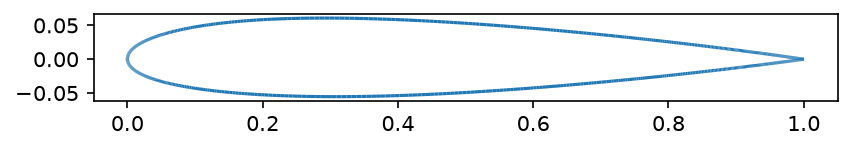

In [ ]:

starts = af_mesh.points[table[:,0],:2]
ends = af_mesh.points[table[:,1],:2]
segs = np.stack([starts, ends], axis=1)

fig, ax = plt.subplots()

ax.add_collection(LineCollection(segs))
ax.autoscale()
ax.set_aspect("equal")
plt.show()